# Predicting Hotel Reservation Cancellations
**CIS 412 – Business Machine Learning · Team Project Phase 2**

**Team:** 99% Confidence
**Members:** Vedika Thareja, Rhys Roberts, Luizeth Denogean, Anthony Caballero, Alexander Salazar, Larissa Backen
**Due:** December 2, 2026

**Project goal:** Build a classification model that predicts whether a hotel reservation will be **canceled** or **not canceled**, find out which booking details matter most, and show how the hotel can use these predictions to protect revenue.

We follow the **CRISP-DM** process: Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment.

**How to run:** In Google Colab click **Runtime → Run all**. When the upload button appears, choose `Hotel_Reservations.csv`.

## 1. Business Understanding

**The problem:** About one out of every three reservations in our data gets canceled. When a booking is canceled close to the arrival date, the room often stays empty, and the hotel loses that revenue. Cancellations also make it hard to plan staffing, food, and how many rooms to overbook.

**How machine learning helps:** If we can predict *which* bookings are likely to cancel, the hotel can act before it happens. For example, it can:
- send reminders or ask for a deposit on high-risk bookings,
- offer a small incentive to keep the booking,
- overbook a safe number of rooms based on expected cancellations.

**Machine learning question:** This is a **binary classification** problem. Target = `booking_status` (1 = Canceled, 0 = Not Canceled).

**Expected impact:** Fewer empty rooms, better occupancy forecasts, smarter overbooking and pricing, and better planning for hotel managers, revenue management, reservations, and marketing teams.

## 2. Setup – Import Libraries

**What this step does:** Loads the Python libraries we need. All of them come preinstalled in Google Colab.
- `pandas` / `numpy` – work with the data table
- `matplotlib` / `seaborn` – make charts
- `scikit-learn` – build and test the machine learning models

**Why:** Every later step uses these tools. We also set `random_state = 42` so everyone in the group gets the same results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

# make charts look clean and the same every time
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

random_state = 42

## 3. Load the Data

**What this step does:** Opens an upload button so any group member can select `Hotel_Reservations.csv` from their computer, then reads it into a table called `hotel_df`.

**Why:** Uploading through Colab means the notebook works for everyone without sharing file paths.

*(If you run this outside of Colab, just keep the CSV in the same folder as the notebook.)*

In [2]:
# Colab upload button (skipped automatically if not running in Colab)
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not running in Colab - reading the CSV from this folder instead.")

hotel_df = pd.read_csv("Hotel_Reservations.csv")
print("Rows and columns:", hotel_df.shape)
hotel_df.head()

Not running in Colab - reading the CSV from this folder instead.
Rows and columns: (36275, 19)


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


## 4. Data Understanding

### 4.1 Structure and data types
**What this step does:** Shows every column, its data type, and how many values it has.

**Why:** We need to know which columns are numbers and which are text categories, because they are handled differently later.

**What it tells the hotel:** The dataset has **36,275 bookings** and **19 columns**: 1 ID, 17 features, and 1 target. 14 columns are numbers (like `lead_time` and `avg_price_per_room`) and 5 are text (meal plan, room type, market segment, booking status, and the ID).

In [3]:
hotel_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  str    
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  str    
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  str    
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date              

### 4.2 Summary statistics
**What this step does:** Shows the average, minimum, maximum, and spread of each numeric column.

**Why:** This helps us spot strange values (outliers) or impossible values.

**What it tells the hotel:** The average booking is made about **85 days** ahead and costs about **$103 per night**. Lead time goes up to 443 days and price goes up to $540, so there are some extreme values. Some bookings also show **0 nights** or a **$0 price**, which we look at in Data Preparation.

In [4]:
hotel_df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.84,0.52,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.11,0.40,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.81,0.87,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.20,1.41,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.03,0.17,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.23,85.93,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.82,0.38,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.42,3.07,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.60,8.74,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.03,0.16,0.0,0.0,0.00,0.0,1.0


### 4.3 Data quality checks
**What this step does:** Counts missing values, exact duplicate rows, impossible dates, zero-night stays, and zero-price rooms.

**Why:** Bad data leads to a bad model, so we need to find problems before modeling.

**What it tells the hotel:** There are **no missing values** and **no exact duplicates** (every row has its own Booking ID). We did find a few problems we fix later:
- some bookings have an arrival date of **February 29, 2018**, which does not exist (2018 was not a leap year)
- some bookings have **0 total nights**
- one booking has a price of **$540**, far above the others

In [5]:
print("Missing values in the whole table:", hotel_df.isnull().sum().sum())
print("Exact duplicate rows:", hotel_df.duplicated().sum())

# rows that are the same in every column except the Booking ID
same_except_id = hotel_df.drop(columns=["Booking_ID"]).duplicated().sum()
print("Rows identical except for Booking ID:", same_except_id)

# impossible dates (for example Feb 29, 2018)
arrival_dates = pd.to_datetime(
    dict(year=hotel_df["arrival_year"], month=hotel_df["arrival_month"], day=hotel_df["arrival_date"]),
    errors="coerce")
print("Impossible arrival dates:", arrival_dates.isnull().sum())

total_nights = hotel_df["no_of_weekend_nights"] + hotel_df["no_of_week_nights"]
print("Bookings with 0 nights:", (total_nights == 0).sum())
print("Bookings with a $0 room price:", (hotel_df["avg_price_per_room"] == 0).sum())
print("Bookings with price over $500:", (hotel_df["avg_price_per_room"] > 500).sum())

Missing values in the whole table: 0
Exact duplicate rows: 0
Rows identical except for Booking ID: 10275
Impossible arrival dates: 37
Bookings with 0 nights: 78
Bookings with a $0 room price: 545
Bookings with price over $500: 1


**Note on the near-duplicates:** About 10,000 rows match another row in every column except the Booking ID. Because each one has its own Booking ID, we treat them as **separate real bookings** (for example, a family or group booking several identical rooms) and keep them. This is a possible source of "noise," and it could make test scores slightly optimistic, so we mention it as a limitation.

**Note on $0 prices:** Most $0 rooms are in the **Complementary** (free) market segment, so they are real and we keep them.

### 4.4 Target variable – how many bookings were canceled?
**What this step does:** Counts canceled vs. not-canceled bookings and draws a bar chart.

**Why:** If one class is much bigger, plain accuracy can be misleading, so we need to know the balance.

**What it tells the hotel:** About **33% of bookings are canceled**. That is a big revenue risk. The classes are somewhat imbalanced (67/33), so we will look at precision, recall, F1, and AUC, not just accuracy.

booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64
booking_status
Not_Canceled    67.2
Canceled        32.8
Name: proportion, dtype: float64


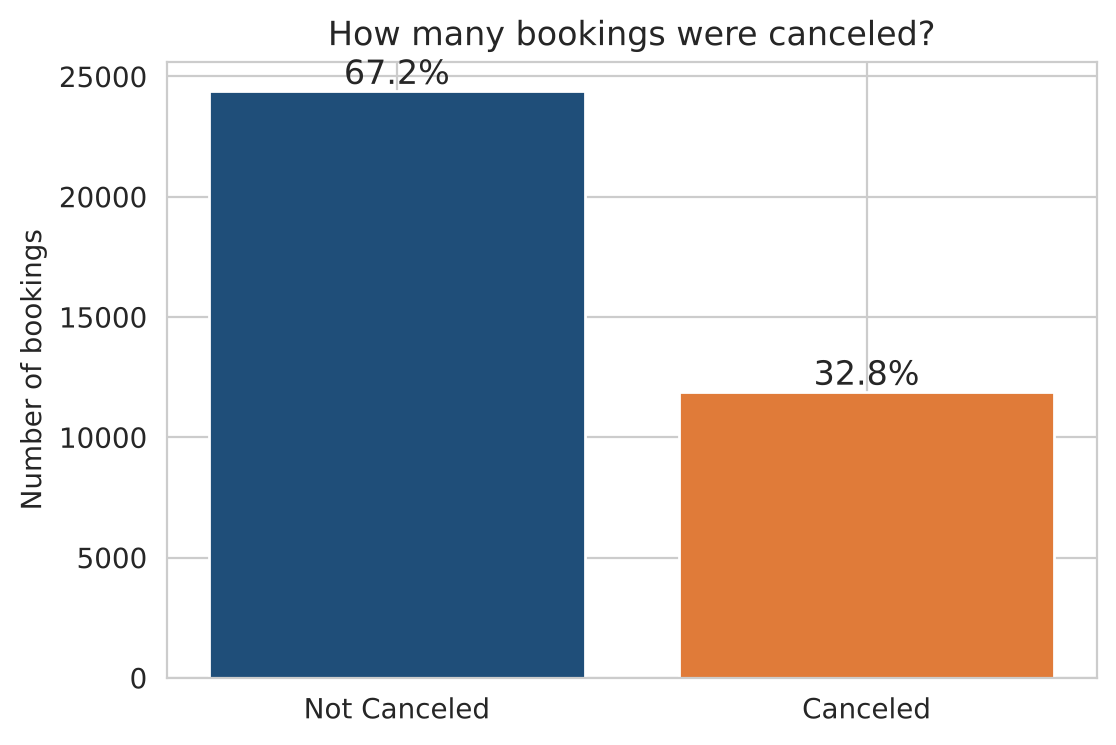

In [6]:
status_counts = hotel_df["booking_status"].value_counts()
status_percent = hotel_df["booking_status"].value_counts(normalize=True) * 100
print(status_counts)
print(status_percent.round(1))

plt.figure(figsize=(6, 4))
bars = plt.bar(["Not Canceled", "Canceled"], status_counts.values, color=["#1F4E79", "#E07B39"])
for bar, pct in zip(bars, status_percent.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 300, f"{pct:.1f}%", ha="center", fontsize=12)
plt.title("How many bookings were canceled?")
plt.ylabel("Number of bookings")
plt.show()

### 4.5 Does booking far in advance lead to more cancellations?
**What this step does:** Groups bookings by lead time (days between booking and arrival) and shows the cancellation rate for each group.

**Why:** We expect people who book far ahead to change their plans more often.

**What it tells the hotel:** Cancellations rise sharply with lead time. Bookings made **within 30 days** cancel about **14%** of the time, while bookings made **more than 180 days ahead** cancel about **74%** of the time. Lead time is likely a key predictor.

lead_time
0-30 days      14.2
31-90 days     25.3
91-180 days    44.9
180+ days      73.9
Name: canceled, dtype: float64


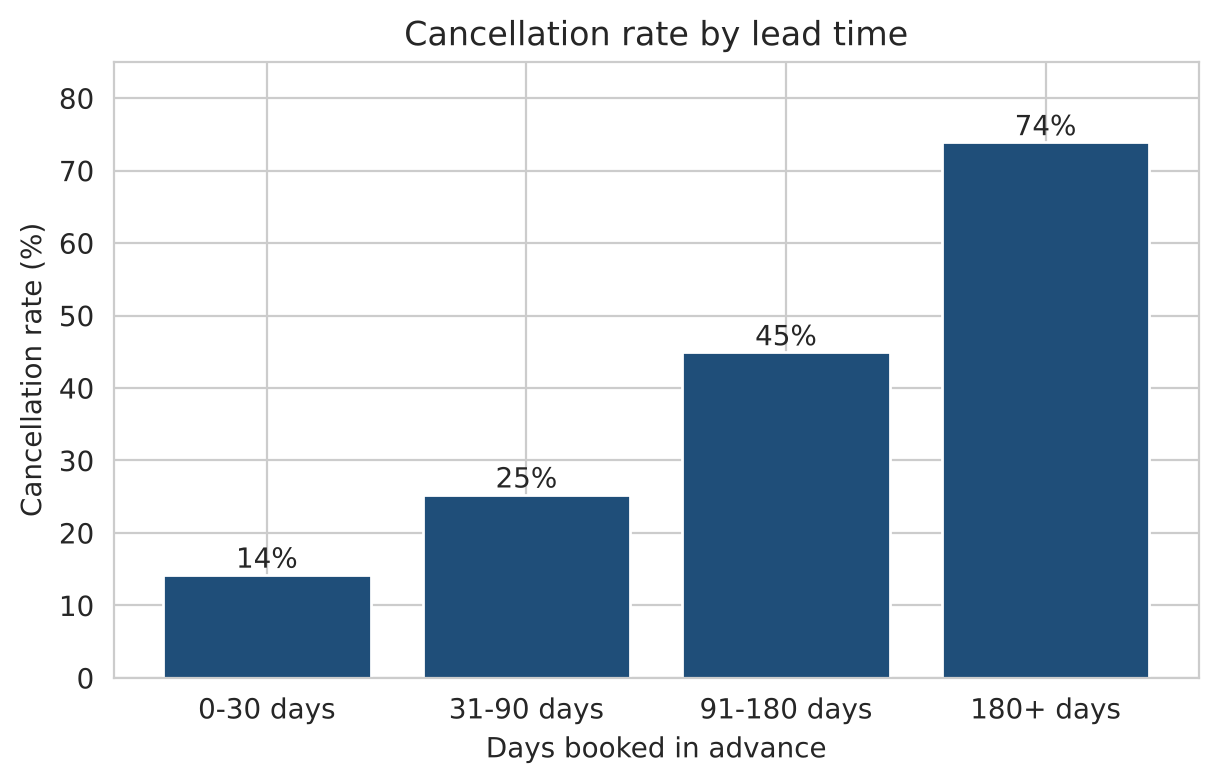

In [7]:
hotel_df["canceled"] = (hotel_df["booking_status"] == "Canceled").astype(int)

lead_time_groups = pd.cut(hotel_df["lead_time"], bins=[-1, 30, 90, 180, 450],
                          labels=["0-30 days", "31-90 days", "91-180 days", "180+ days"])
cancel_rate_by_lead = hotel_df.groupby(lead_time_groups, observed=True)["canceled"].mean() * 100
print(cancel_rate_by_lead.round(1))

plt.figure(figsize=(7, 4))
bars = plt.bar(cancel_rate_by_lead.index.astype(str), cancel_rate_by_lead.values, color="#1F4E79")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{bar.get_height():.0f}%", ha="center")
plt.title("Cancellation rate by lead time")
plt.xlabel("Days booked in advance")
plt.ylabel("Cancellation rate (%)")
plt.ylim(0, 85)
plt.show()

### 4.6 Do special requests and market segment matter?
**What this step does:** Shows the cancellation rate by number of special requests and by market segment (how the booking was made).

**Why:** Guests who add requests (like a high floor or extra bed) may be more committed. Online bookings may be easier to cancel.

**What it tells the hotel:** Guests with **no special requests** cancel about **43%** of the time, while guests with **3 or more requests almost never cancel**. **Online** bookings cancel most often (about **37%**), while **Corporate** bookings cancel only about **11%** of the time.

no_of_special_requests
0    43.2
1    23.8
2    14.6
3     0.0
4     0.0
5     0.0
Name: canceled, dtype: float64
market_segment_type
Online           36.5
Offline          29.9
Aviation         29.6
Corporate        10.9
Complementary     0.0
Name: canceled, dtype: float64


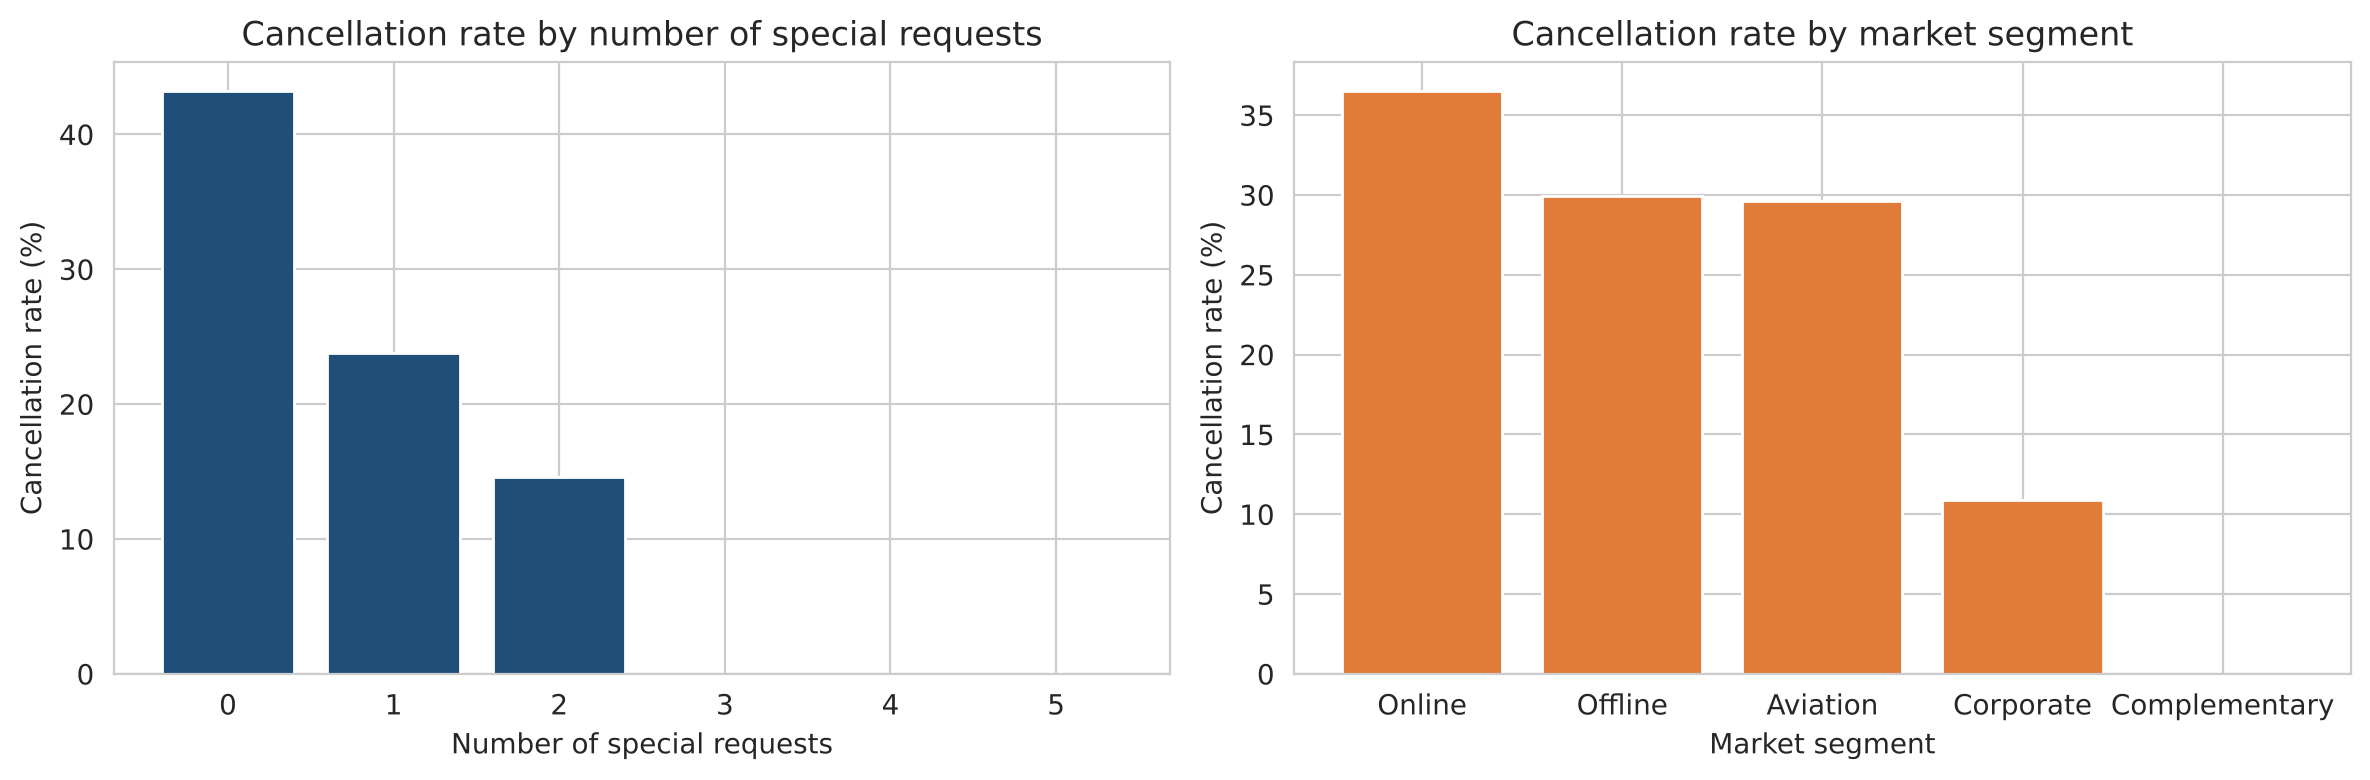

In [8]:
cancel_rate_by_requests = hotel_df.groupby("no_of_special_requests")["canceled"].mean() * 100
cancel_rate_by_segment = hotel_df.groupby("market_segment_type")["canceled"].mean().sort_values(ascending=False) * 100
print(cancel_rate_by_requests.round(1))
print(cancel_rate_by_segment.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(cancel_rate_by_requests.index.astype(str), cancel_rate_by_requests.values, color="#1F4E79")
axes[0].set_title("Cancellation rate by number of special requests")
axes[0].set_xlabel("Number of special requests")
axes[0].set_ylabel("Cancellation rate (%)")

axes[1].bar(cancel_rate_by_segment.index, cancel_rate_by_segment.values, color="#E07B39")
axes[1].set_title("Cancellation rate by market segment")
axes[1].set_xlabel("Market segment")
axes[1].set_ylabel("Cancellation rate (%)")

plt.tight_layout()
plt.show()

### 4.7 Room price and cancellations
**What this step does:** Compares the room price for canceled vs. not-canceled bookings using a box plot.

**Why:** Higher prices might push guests to look for cheaper options and cancel.

**What it tells the hotel:** Canceled bookings have a slightly **higher typical price** than kept bookings. Price matters, but less than lead time.

booking_status
Canceled        108.0
Not_Canceled     95.0
Name: avg_price_per_room, dtype: float64


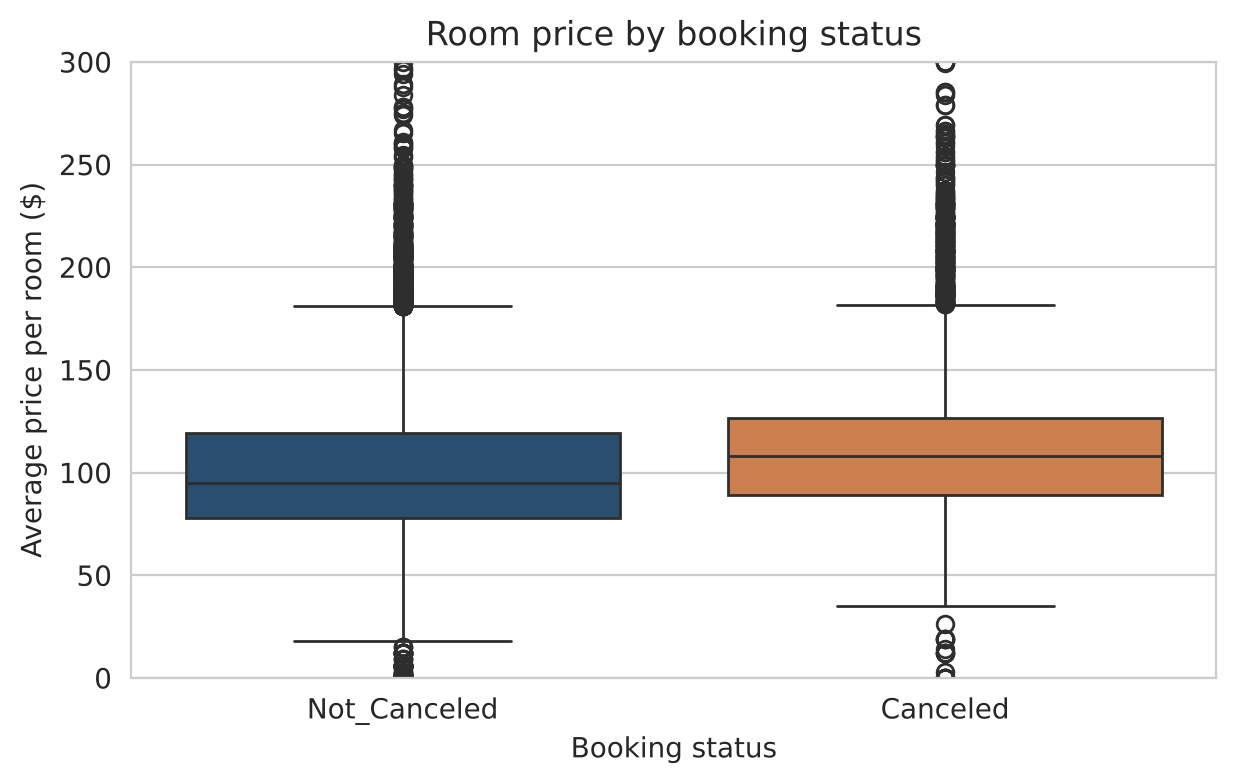

In [9]:
print(hotel_df.groupby("booking_status")["avg_price_per_room"].median())

plt.figure(figsize=(7, 4))
sns.boxplot(data=hotel_df, x="booking_status", y="avg_price_per_room",
            hue="booking_status", palette=["#1F4E79", "#E07B39"], legend=False)
plt.title("Room price by booking status")
plt.xlabel("Booking status")
plt.ylabel("Average price per room ($)")
plt.ylim(0, 300)
plt.show()

### 4.8 Relationships between numeric variables
**What this step does:** Draws a correlation heatmap. Values near +1 or -1 mean two columns move together strongly; values near 0 mean little relationship.

**Why:** It helps us see which features relate to cancellations and whether any features are almost copies of each other.

**What it tells the hotel:** `lead_time` has the strongest positive link with cancellation, and `no_of_special_requests` has the strongest negative link. No two features are so similar that we need to remove one.

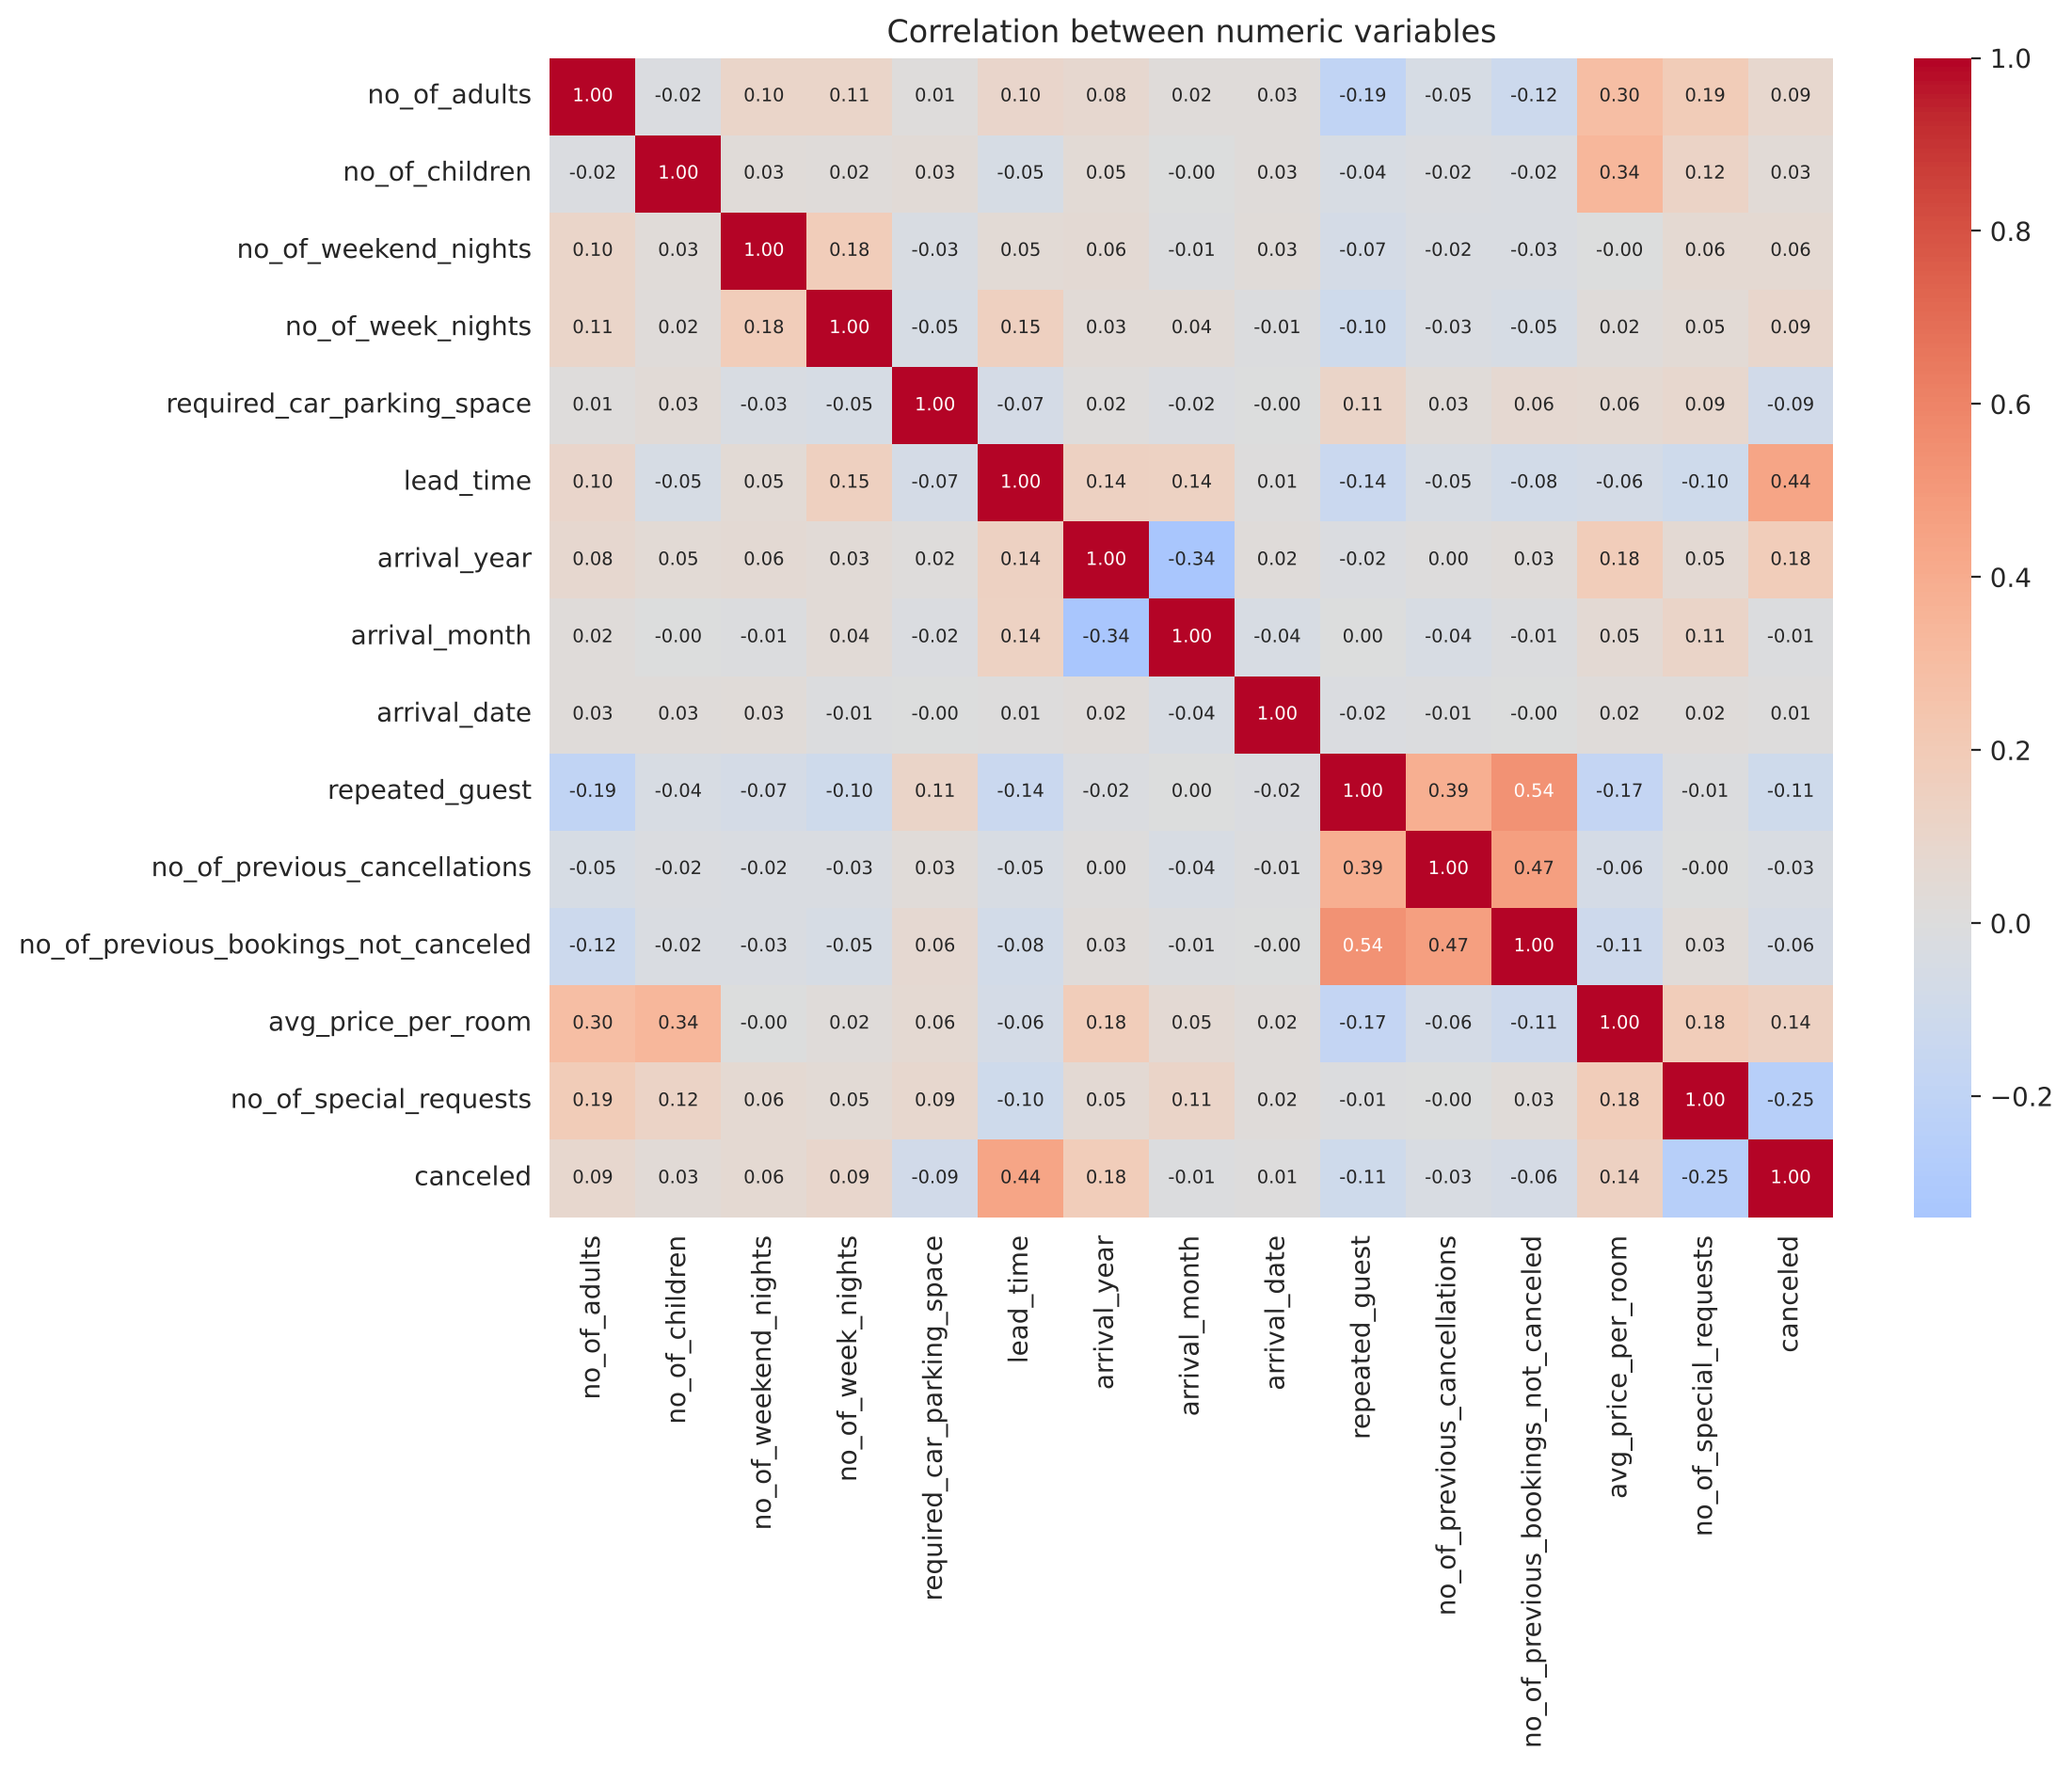

no_of_special_requests                 -0.25
repeated_guest                         -0.11
required_car_parking_space             -0.09
no_of_previous_bookings_not_canceled   -0.06
no_of_previous_cancellations           -0.03
arrival_month                          -0.01
arrival_date                            0.01
no_of_children                          0.03
no_of_weekend_nights                    0.06
no_of_adults                            0.09
no_of_week_nights                       0.09
avg_price_per_room                      0.14
arrival_year                            0.18
lead_time                               0.44
Name: canceled, dtype: float64


In [10]:
numeric_columns = hotel_df.select_dtypes(include="number")
correlation_table = numeric_columns.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation_table, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation between numeric variables")
plt.show()

print(correlation_table["canceled"].drop("canceled").sort_values().round(2))

## 5. Data Preparation

Our cleaning and preprocessing steps:
1. Drop the `Booking_ID` column (it is just a label, not useful for prediction)
2. Remove impossible arrival dates (Feb 29, 2018)
3. Remove bookings with 0 nights (not a real stay)
4. Remove the extreme price outlier (over $500)
5. Feature engineering: create `total_nights` and `total_guests`
6. Drop `arrival_year` and `arrival_date` (day of month) since they will not help predict future bookings; keep `arrival_month` for seasonality
7. Turn the target into 1 = Canceled, 0 = Not Canceled
8. One-hot encode the text columns (meal plan, room type, market segment)
9. Split into 80% training and 20% testing data
10. Scale (normalize) the numbers so they are on the same scale

There were **no missing values**, so no filling in (imputation) was needed.

### 5.1 Clean the rows
**What this step does:** Removes the ID column and the bad rows we found in Data Understanding.

**Why:** Impossible dates, zero-night stays, and an extreme price would confuse the model.

**What it tells the hotel:** We only lose a very small share of rows (well under 1%), so the data is still a good picture of the hotel's bookings.

In [11]:
clean_df = hotel_df.copy()
rows_before = len(clean_df)

# Step 1: drop the ID column and the helper column we made for charts
clean_df = clean_df.drop(columns=["Booking_ID", "canceled"])

# Step 2: remove impossible dates
arrival_dates = pd.to_datetime(
    dict(year=clean_df["arrival_year"], month=clean_df["arrival_month"], day=clean_df["arrival_date"]),
    errors="coerce")
clean_df = clean_df[arrival_dates.notnull()]

# Step 3: remove bookings with 0 nights
clean_df = clean_df[(clean_df["no_of_weekend_nights"] + clean_df["no_of_week_nights"]) > 0]

# Step 4: remove the extreme price outlier
clean_df = clean_df[clean_df["avg_price_per_room"] <= 500]

rows_after = len(clean_df)
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before cleaning: 36275
Rows after cleaning: 36159
Rows removed: 116


### 5.2 Feature engineering and encoding
**What this step does:**
- Creates two new, easier-to-understand features: `total_nights` (weekend + week nights) and `total_guests` (adults + children).
- Drops `arrival_year` and `arrival_date`.
- Changes the target to numbers: 1 = Canceled, 0 = Not Canceled.
- **One-hot encodes** the text columns. For example, `market_segment_type` becomes separate 0/1 columns like `market_segment_type_Online`. We use `drop_first=True` to avoid repeating information.

**Why:** Machine learning models need numbers, not text. New features can make patterns clearer.

**What it tells the hotel:** The model can now use every booking detail, including meal plan, room type, and how the booking was made.

In [12]:
# Step 5: new features
clean_df["total_nights"] = clean_df["no_of_weekend_nights"] + clean_df["no_of_week_nights"]
clean_df["total_guests"] = clean_df["no_of_adults"] + clean_df["no_of_children"]

# Step 6: drop columns that will not help predict future bookings
clean_df = clean_df.drop(columns=["arrival_year", "arrival_date"])

# Step 7: target to numbers
clean_df["booking_status"] = clean_df["booking_status"].map({"Canceled": 1, "Not_Canceled": 0})

# Step 8: one-hot encode the text columns
text_columns = ["type_of_meal_plan", "room_type_reserved", "market_segment_type"]
model_df = pd.get_dummies(clean_df, columns=text_columns, drop_first=True, dtype=int)

print("Columns after encoding:", model_df.shape[1])
model_df.head()

Columns after encoding: 28


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_month,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,...,room_type_reserved_Room_Type 2,room_type_reserved_Room_Type 3,room_type_reserved_Room_Type 4,room_type_reserved_Room_Type 5,room_type_reserved_Room_Type 6,room_type_reserved_Room_Type 7,market_segment_type_Complementary,market_segment_type_Corporate,market_segment_type_Offline,market_segment_type_Online
0,2,0,1,2,0,224,10,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,2,0,2,3,0,5,11,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,1,0,2,1,0,1,2,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,2,0,0,2,0,211,5,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,2,0,1,1,0,48,4,0,0,0,...,0,0,0,0,0,0,0,0,0,1


### 5.3 Split into training and testing sets
**What this step does:** Separates the features (`X`) from the target (`y`), then keeps **80%** of bookings for training and holds back **20%** for testing. `stratify=y` keeps the same 33% cancellation rate in both sets.

**Why:** Testing on data the model has never seen tells us how well it will work on **new** bookings, which is what the hotel actually cares about.

In [13]:
X = model_df.drop(columns=["booking_status"])
y = model_df["booking_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_state, stratify=y)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Cancellation rate in training set:", round(y_train.mean() * 100, 1), "%")
print("Cancellation rate in testing set:", round(y_test.mean() * 100, 1), "%")

Training rows: 28927
Testing rows: 7232
Number of features: 27
Cancellation rate in training set: 32.8 %
Cancellation rate in testing set: 32.8 %


### 5.4 Normalize (scale) the features
**What this step does:** Uses `StandardScaler` so every feature has an average of 0 and the same spread.

**Why:** Lead time goes up to 443 while most other columns are small numbers like 0, 1, or 2. Logistic regression and SVM can be thrown off by these different scales. (Decision trees and random forests are not affected, but scaling does not hurt them.) We **fit the scaler on the training data only** so no information from the test set leaks into training.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Average of lead_time after scaling (train):", round(X_train_scaled[:, list(X.columns).index("lead_time")].mean(), 2))

Average of lead_time after scaling (train): 0.0


## 6. Modeling

**Type of problem:** Supervised **binary classification** (predict Canceled = 1 or Not Canceled = 0).

We build the four models from our proposal:
| Model | Simple explanation |
|---|---|
| **Decision Tree** | Asks a series of yes/no questions (e.g., "Is lead time over 150 days?") to reach a prediction. Easy to explain. |
| **Logistic Regression** | Gives each feature a weight and turns the total into a probability of cancellation. Simple baseline. |
| **Random Forest** | An **ensemble** of many decision trees that each vote. Usually more accurate and less likely to overfit than one tree. |
| **Support Vector Machine (Linear SVM)** | Finds the best dividing line (boundary) between canceled and kept bookings. We use the linear version because the regular SVM is very slow on 29,000 rows. |

**Metrics we use:**
- **Accuracy** – % of all predictions that are correct
- **Precision** – of the bookings we *flag* as cancellations, % that really cancel
- **Recall** – of the bookings that *really* cancel, % we catch
- **F1 score** – a balance of precision and recall

### 6.1 Train the four models
**What this step does:** Fits each model on the training data. We start with default settings (we tune them later in Evaluation).

In [15]:
decision_tree = DecisionTreeClassifier(random_state=random_state)
decision_tree.fit(X_train_scaled, y_train)

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

random_forest = RandomForestClassifier(random_state=random_state, n_jobs=-1)
random_forest.fit(X_train_scaled, y_train)

svm_model = LinearSVC(random_state=random_state, max_iter=5000)
svm_model.fit(X_train_scaled, y_train)

print("All four models are trained.")

All four models are trained.


### 6.2 Performance on the training set
**What this step does:** Scores each model on the same data it learned from.

**Why:** The rubric asks us to look at training performance. Comparing it later to test performance shows whether a model is **overfitting** (memorizing the training data instead of learning general patterns).

In [16]:
models = {
    "Decision Tree": decision_tree,
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest,
    "Linear SVM": svm_model,
}

training_results = []
for model_name, model in models.items():
    train_predictions = model.predict(X_train_scaled)
    training_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_train, train_predictions),
        "Precision": precision_score(y_train, train_predictions),
        "Recall": recall_score(y_train, train_predictions),
        "F1": f1_score(y_train, train_predictions),
    })

training_table = pd.DataFrame(training_results).set_index("Model").round(3)
training_table

,Accuracy,Precision,Recall,F1
Model,,,,
Decision Tree,0.993,0.996,0.983,0.990
Logistic Regression,0.800,0.730,0.621,0.671
Random Forest,0.993,0.994,0.985,0.990
Linear SVM,0.799,0.733,0.613,0.667


**What the training results tell us:**
- The **Decision Tree** and **Random Forest** score almost perfectly on the training data. That is a warning sign of **overfitting**: they may have memorized the training bookings.
- **Logistic Regression** and **Linear SVM** score lower (around 80% accuracy) but similar to each other. These simpler models cannot memorize as easily, so their training scores are a more honest guess of how they will do on new data.
- We check this in the next section by scoring every model on the **test set**.

## 7. Evaluation

### 7.1 Performance on the test set
**What this step does:** Scores each model on the 20% of bookings it has **never seen**. We also add **AUC** (area under the ROC curve), which measures how well the model ranks risky bookings above safe ones, across all thresholds (0.5 = random guessing, 1.0 = perfect).

**Why:** Test results are the best estimate of real-world performance.

In [17]:
test_results = []
for model_name, model in models.items():
    test_predictions = model.predict(X_test_scaled)

    # AUC needs a score, not just a yes/no prediction
    if model_name == "Linear SVM":
        test_scores = model.decision_function(X_test_scaled)
    else:
        test_scores = model.predict_proba(X_test_scaled)[:, 1]

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, test_predictions),
        "Precision": precision_score(y_test, test_predictions),
        "Recall": recall_score(y_test, test_predictions),
        "F1": f1_score(y_test, test_predictions),
        "AUC": roc_auc_score(y_test, test_scores),
    })

test_table = pd.DataFrame(test_results).set_index("Model").round(3)
test_table

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Decision Tree,0.867,0.788,0.813,0.800,0.856
Logistic Regression,0.806,0.738,0.632,0.681,0.866
Random Forest,0.901,0.882,0.806,0.842,0.954
Linear SVM,0.802,0.737,0.618,0.672,0.866


### 7.2 Training vs. test – checking for overfitting
**What this step does:** Puts training and test accuracy side by side.

**What it tells us:** A big gap between training and test accuracy means overfitting. The single **Decision Tree** has the biggest gap. The **Random Forest** also drops from training to test, but it still has the **highest test score**, because averaging many trees cancels out a lot of the memorizing.

                     Training Accuracy  Test Accuracy    Gap
Model                                                       
Decision Tree                    0.993          0.867  0.126
Logistic Regression              0.800          0.806 -0.006
Random Forest                    0.993          0.901  0.092
Linear SVM                       0.799          0.802 -0.003


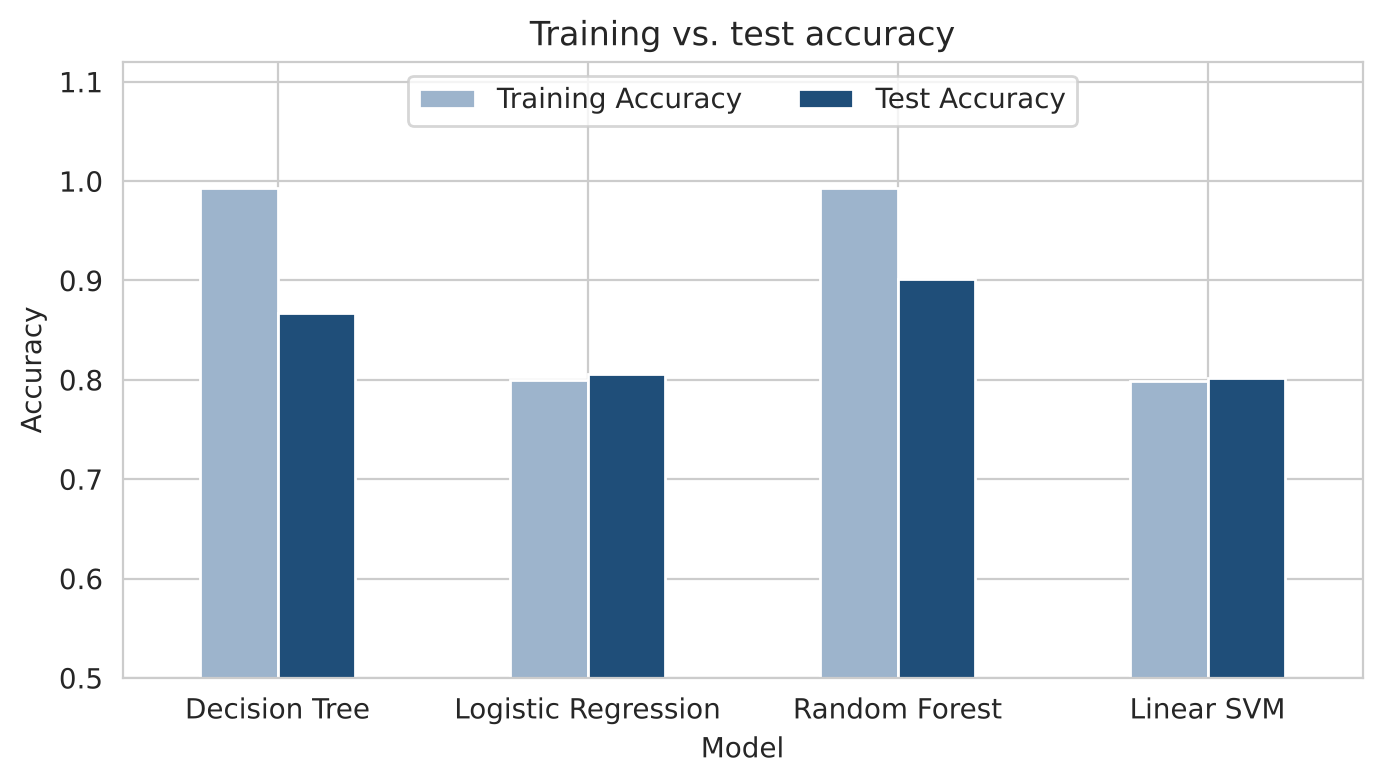

In [18]:
accuracy_compare = pd.DataFrame({
    "Training Accuracy": training_table["Accuracy"],
    "Test Accuracy": test_table["Accuracy"],
})
accuracy_compare["Gap"] = (accuracy_compare["Training Accuracy"] - accuracy_compare["Test Accuracy"]).round(3)
print(accuracy_compare)

accuracy_compare[["Training Accuracy", "Test Accuracy"]].plot(kind="bar", color=["#9DB4CC", "#1F4E79"], figsize=(8, 4))
plt.title("Training vs. test accuracy")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.12)
plt.xticks(rotation=0)
plt.legend(loc="upper center", ncol=2)
plt.show()

### 7.3 ROC curves
**What this step does:** Draws an ROC curve for each model. The x-axis is the **False Positive Rate** (FPR = FP / (FP + TN), kept bookings we wrongly flag) and the y-axis is the **True Positive Rate** (TPR = TP / (TP + FN), real cancellations we catch). The dashed diagonal line is random guessing.

**Why:** ROC curves show performance at **every** threshold, so they are not tied to the 0.5 cutoff. A curve closer to the top-left corner is better.

**What it tells the hotel:** The **Random Forest** curve is the highest (AUC about 0.95), so it is the best at separating risky bookings from safe ones. Logistic Regression and Linear SVM have almost the same curve (both AUC about 0.87), so their lines sit on top of each other. The single Decision Tree has the lowest AUC because it gives very "yes or no" probabilities.

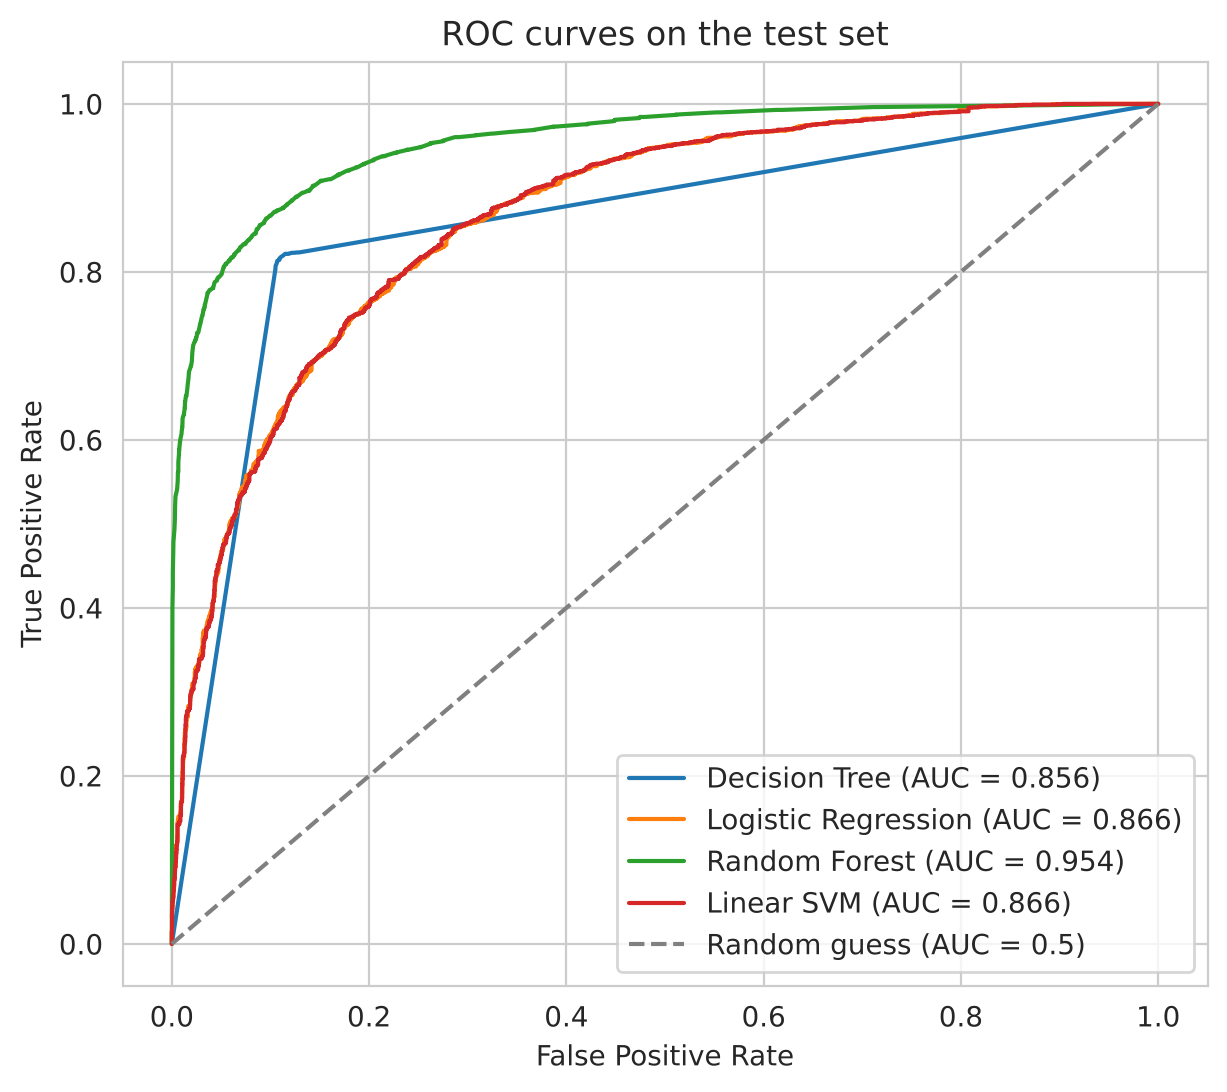

In [19]:
plt.figure(figsize=(7, 6))
for model_name, model in models.items():
    if model_name == "Linear SVM":
        test_scores = model.decision_function(X_test_scaled)
    else:
        test_scores = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, test_scores)
    auc_value = roc_auc_score(y_test, test_scores)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.show()

### 7.4 Improving the models – grid search with cross-validation
**What this step does:** Uses `GridSearchCV` to try different settings (hyperparameters) and picks the best combination using **5-fold cross-validation**. In 5-fold CV the training data is split into 5 parts; the model trains on 4 and is checked on the 5th, five times, and the scores are averaged. We use **F1** as the score because we care about catching cancellations, not just overall accuracy.

- **Decision Tree:** limit how deep the tree can grow (`max_depth`) and the minimum bookings per leaf (`min_samples_leaf`) to reduce overfitting.
- **Random Forest:** try different numbers of trees (`n_estimators`) and depths.

**Why:** This is how we tune a model without peeking at the test set. *(This cell takes about 1–2 minutes in Colab.)*

In [20]:
# --- Decision Tree grid search ---
tree_settings = {
    "max_depth": [5, 10, 15, 20],
    "min_samples_leaf": [1, 5, 10],
}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=random_state),
                           tree_settings, cv=5, scoring="f1", n_jobs=-1)
tree_search.fit(X_train_scaled, y_train)
print("Best Decision Tree settings:", tree_search.best_params_)
print("Best Decision Tree CV F1:", round(tree_search.best_score_, 3))

# --- Random Forest grid search ---
forest_settings = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
}
forest_search = GridSearchCV(RandomForestClassifier(random_state=random_state),
                             forest_settings, cv=5, scoring="f1", n_jobs=-1)
forest_search.fit(X_train_scaled, y_train)
print("Best Random Forest settings:", forest_search.best_params_)
print("Best Random Forest CV F1:", round(forest_search.best_score_, 3))

Best Decision Tree settings: {'max_depth': 15, 'min_samples_leaf': 1}
Best Decision Tree CV F1: 0.797


Best Random Forest settings: {'max_depth': 20, 'n_estimators': 200}
Best Random Forest CV F1: 0.83


In [21]:
# Score the tuned models on the test set
tuned_models = {
    "Decision Tree (tuned)": tree_search.best_estimator_,
    "Random Forest (tuned)": forest_search.best_estimator_,
}

tuned_results = []
for model_name, model in tuned_models.items():
    test_predictions = model.predict(X_test_scaled)
    test_scores = model.predict_proba(X_test_scaled)[:, 1]
    train_accuracy = accuracy_score(y_train, model.predict(X_train_scaled))
    tuned_results.append({
        "Model": model_name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": accuracy_score(y_test, test_predictions),
        "Precision": precision_score(y_test, test_predictions),
        "Recall": recall_score(y_test, test_predictions),
        "F1": f1_score(y_test, test_predictions),
        "AUC": roc_auc_score(y_test, test_scores),
    })

tuned_table = pd.DataFrame(tuned_results).set_index("Model").round(3)
tuned_table

,Train Accuracy,Test Accuracy,Precision,Recall,F1,AUC
Model,,,,,,
Decision Tree (tuned),0.929,0.878,0.826,0.795,0.810,0.911
Random Forest (tuned),0.954,0.899,0.880,0.800,0.838,0.958


**What tuning tells us:**
- **Decision Tree:** limiting the depth to 15 cut the training/test gap from about 12.6 points to about 5 points, and test accuracy went **up** (0.867 → 0.878) and AUC went up a lot (0.856 → 0.911). Less overfitting = better on new bookings.
- **Random Forest:** limiting depth to 20 with 200 trees cut the gap from about 9 points to about 5.5 points. Test accuracy stayed about the same (≈0.90) and AUC went up slightly (0.954 → 0.958).
- The tuned Random Forest is still the best model on every test metric, so it is our **final model**.

### 7.5 Is the result stable? – 5-fold cross-validation of the final model
**What this step does:** Runs 5-fold cross-validation on the final Random Forest and reports the average accuracy and how much it varies.

**Why:** One train/test split could be lucky. If the five scores are close together, we can trust the result.

In [22]:
final_model = forest_search.best_estimator_

cv_accuracy_scores = cross_val_score(final_model, X_train_scaled, y_train, cv=5, scoring="accuracy", n_jobs=-1)
print("Accuracy for each of the 5 folds:", cv_accuracy_scores.round(3))
print("Average CV accuracy:", round(cv_accuracy_scores.mean(), 3))
print("Standard deviation:", round(cv_accuracy_scores.std(), 3))

Accuracy for each of the 5 folds: [0.892 0.89  0.903 0.888 0.893]
Average CV accuracy: 0.893
Standard deviation: 0.005


### 7.6 Confusion matrix for the final model
**What this step does:** Shows exactly how many test bookings were predicted correctly and incorrectly.
- **True Positive (TP):** predicted cancel, really canceled
- **False Positive (FP):** predicted cancel, but the guest showed up
- **False Negative (FN):** predicted keep, but the guest canceled
- **True Negative (TN):** predicted keep, guest showed up

**What it tells the hotel:** FPs are the costly mistake if the hotel overbooks (a guest arrives and there is no room). FNs are missed revenue (an empty room the hotel did not plan for).

True Negatives: 4597  False Positives: 260
False Negatives: 474  True Positives: 1901


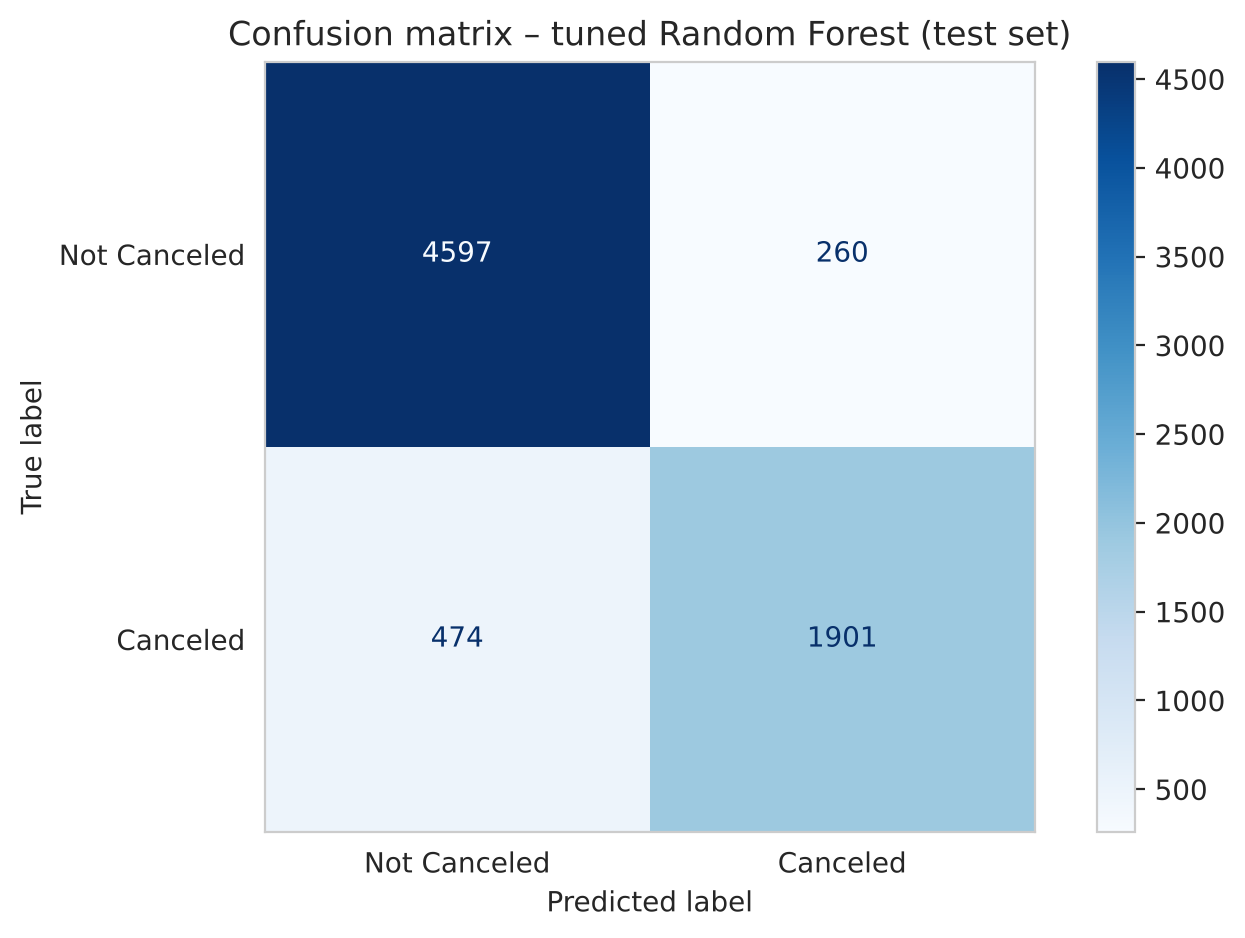

In [23]:
final_predictions = final_model.predict(X_test_scaled)
final_probabilities = final_model.predict_proba(X_test_scaled)[:, 1]

final_matrix = confusion_matrix(y_test, final_predictions)
tn, fp, fn, tp = final_matrix.ravel()
print("True Negatives:", tn, " False Positives:", fp)
print("False Negatives:", fn, " True Positives:", tp)

display_matrix = ConfusionMatrixDisplay(final_matrix, display_labels=["Not Canceled", "Canceled"])
display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix – tuned Random Forest (test set)")
plt.grid(False)
plt.show()

### 7.7 Changing the threshold
**What this step does:** By default a booking is flagged when its predicted chance of canceling is over **0.5**. Here we try 0.3, 0.5, and 0.7.

**Why:** **Lowering** the threshold flags more bookings, so we catch more real cancellations (higher recall) but also flag more guests who would have shown up (lower precision). **Raising** it does the opposite.

**What it tells the hotel:** The hotel can pick the threshold that fits its action. A cheap action like a reminder email can use a **low** threshold. A risky action like overbooking should use a **high** threshold.

In [24]:
threshold_results = []
for threshold in [0.3, 0.5, 0.7]:
    flagged = (final_probabilities >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, flagged).ravel()
    threshold_results.append({
        "Threshold": threshold,
        "Bookings flagged": int(flagged.sum()),
        "True Positives": tp_t,
        "False Positives": fp_t,
        "Precision": round(precision_score(y_test, flagged), 3),
        "Recall": round(recall_score(y_test, flagged), 3),
    })

threshold_table = pd.DataFrame(threshold_results)
threshold_table

,Threshold,Bookings flagged,True Positives,False Positives,Precision,Recall
0,0.3,2698,2122,576,0.787,0.893
1,0.5,2161,1901,260,0.880,0.800
2,0.7,1639,1564,75,0.954,0.659


### 7.8 Cumulative response and lift
**What this step does:** Ranks test bookings from highest to lowest predicted risk. The **cumulative response curve** shows what % of all cancellations we catch if we only contact the top X% riskiest bookings. **Lift** compares that to picking bookings at random (lift = rate of cancellations among the bookings we target ÷ overall cancellation rate).

**Why:** Hotels have limited staff time. This shows how much better the model is than guessing.

**What it tells the hotel:** A lift **greater than 1** means the model beats random selection. By contacting just the top 10% riskiest bookings, the hotel reaches cancellations about **3 times** more often than picking at random.

   Top % of bookings targeted  % of all cancellations caught  Lift
0                          10                           30.4  3.04
1                          20                           59.2  2.96
2                          30                           80.3  2.68
3                          50                           96.0  1.92


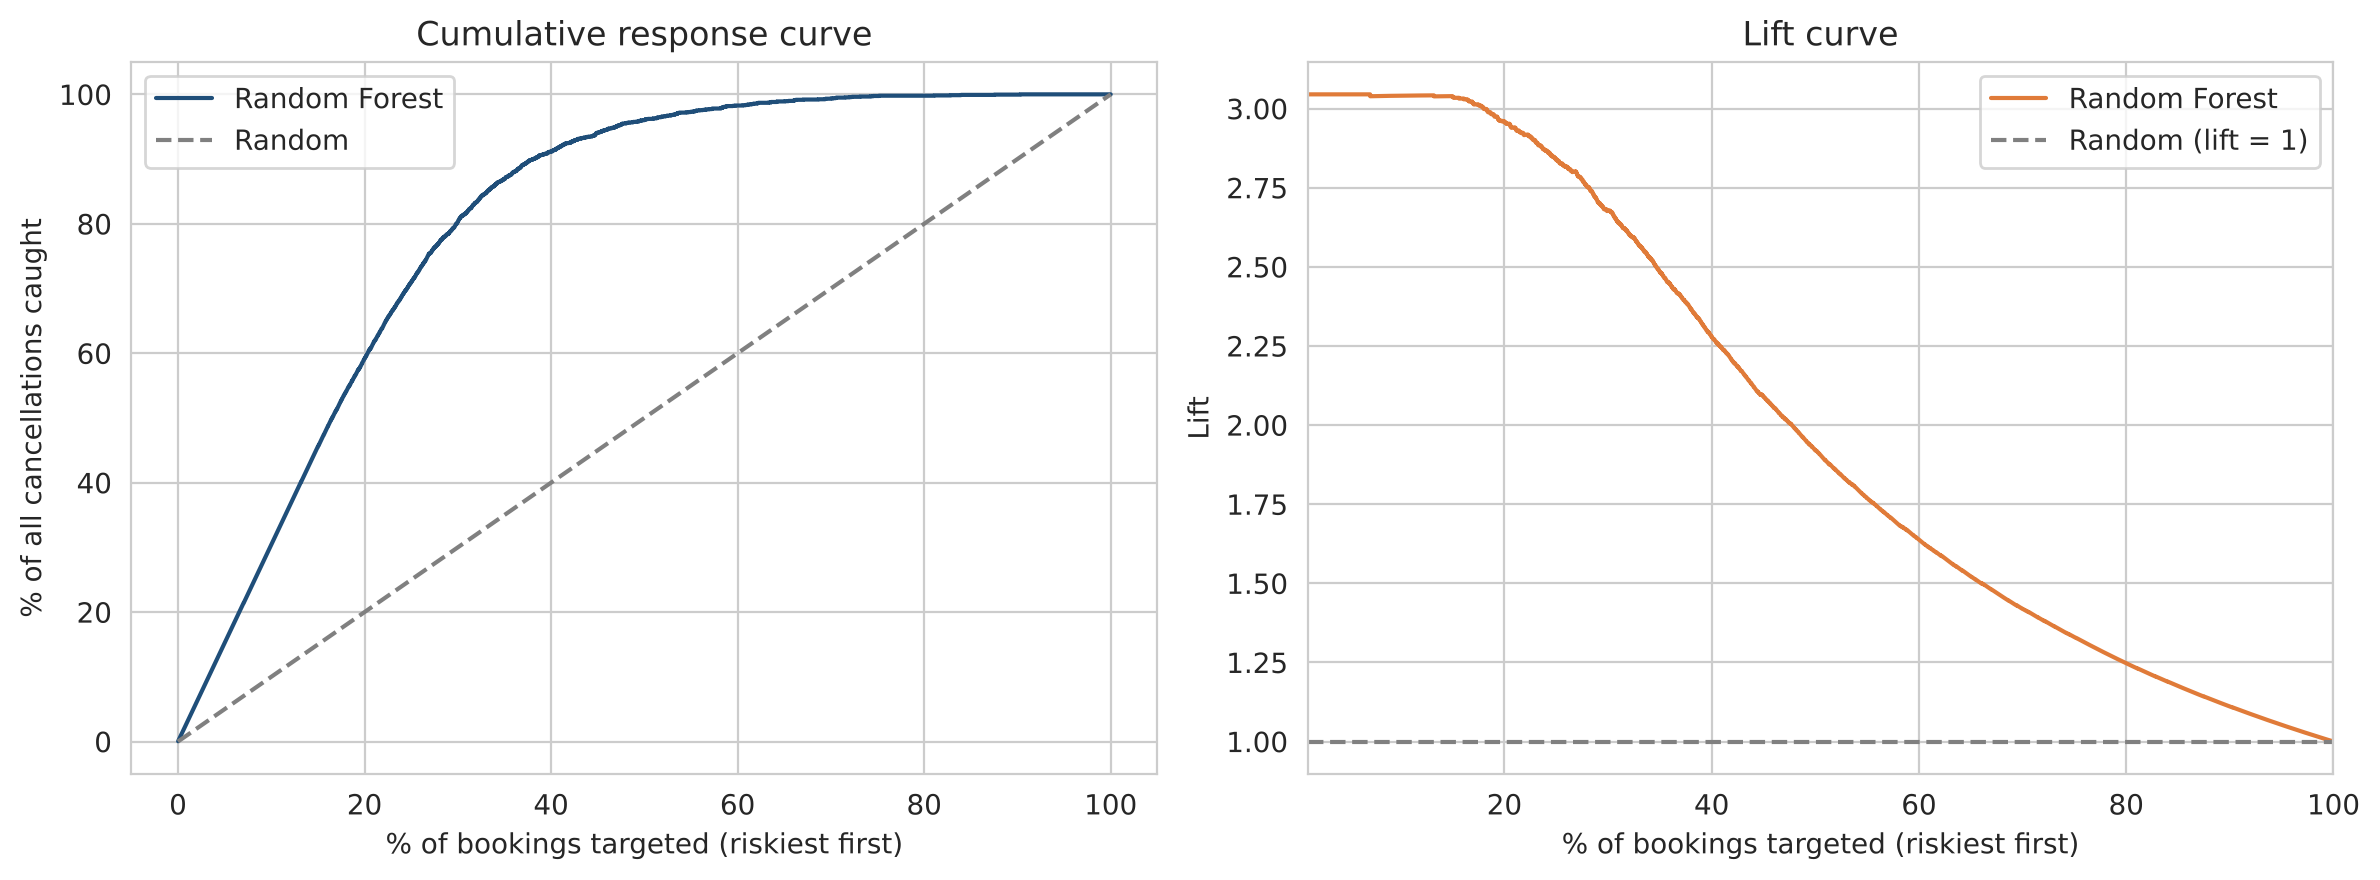

In [25]:
ranking_df = pd.DataFrame({"actual": y_test.values, "probability": final_probabilities})
ranking_df = ranking_df.sort_values("probability", ascending=False).reset_index(drop=True)

total_bookings = len(ranking_df)
total_cancellations = ranking_df["actual"].sum()
overall_cancel_rate = total_cancellations / total_bookings

ranking_df["percent_targeted"] = (ranking_df.index + 1) / total_bookings * 100
ranking_df["percent_cancellations_caught"] = ranking_df["actual"].cumsum() / total_cancellations * 100
ranking_df["lift"] = (ranking_df["actual"].cumsum() / (ranking_df.index + 1)) / overall_cancel_rate

# lift at the top 10%, 20%, 30%, and 50%
lift_rows = []
for percent in [10, 20, 30, 50]:
    row_number = int(total_bookings * percent / 100) - 1
    lift_rows.append({
        "Top % of bookings targeted": percent,
        "% of all cancellations caught": round(ranking_df.loc[row_number, "percent_cancellations_caught"], 1),
        "Lift": round(ranking_df.loc[row_number, "lift"], 2),
    })
lift_table = pd.DataFrame(lift_rows)
print(lift_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ranking_df["percent_targeted"], ranking_df["percent_cancellations_caught"], color="#1F4E79", label="Random Forest")
axes[0].plot([0, 100], [0, 100], linestyle="--", color="gray", label="Random")
axes[0].set_title("Cumulative response curve")
axes[0].set_xlabel("% of bookings targeted (riskiest first)")
axes[0].set_ylabel("% of all cancellations caught")
axes[0].legend()

axes[1].plot(ranking_df["percent_targeted"], ranking_df["lift"], color="#E07B39", label="Random Forest")
axes[1].axhline(1, linestyle="--", color="gray", label="Random (lift = 1)")
axes[1].set_title("Lift curve")
axes[1].set_xlabel("% of bookings targeted (riskiest first)")
axes[1].set_ylabel("Lift")
axes[1].set_xlim(1, 100)
axes[1].legend()

plt.tight_layout()
plt.show()

### 7.9 Profit curve – how many rooms should the hotel overbook?
**What this step does:** Puts dollar values on the model's decisions. ROC and lift do not include costs, but a profit curve does. We use **simple example assumptions**:
- If we overbook a room for a booking that **really cancels** (TP), the hotel gains one night of revenue, about the **average room price** (~$103).
- If we overbook a room for a guest who **does show up** (FP), the hotel pays about **$150** to move that guest to another hotel and make up for it.

We then add up profit as we target more and more of the riskiest bookings.

**Why:** The "best" model or threshold depends on business costs and how many bookings the hotel can act on.

**What it tells the hotel:** Profit rises at first (we are mostly catching real cancellations), peaks when we target about the **riskiest 27%** of bookings (a predicted probability of about 0.59 or higher), and then falls when we start overbooking guests who will show up. The peak tells the hotel how much of its booking list it can safely overbook. *(These dollar values are assumptions for illustration; the hotel should replace them with its own numbers.)*

Benefit per correct overbooking: $ 103.65
Cost per wrong overbooking: $ 150
Best % of bookings to target: 26.9 %
Probability cutoff at that point: 0.59
Estimated profit on the test set: $ 162084.0


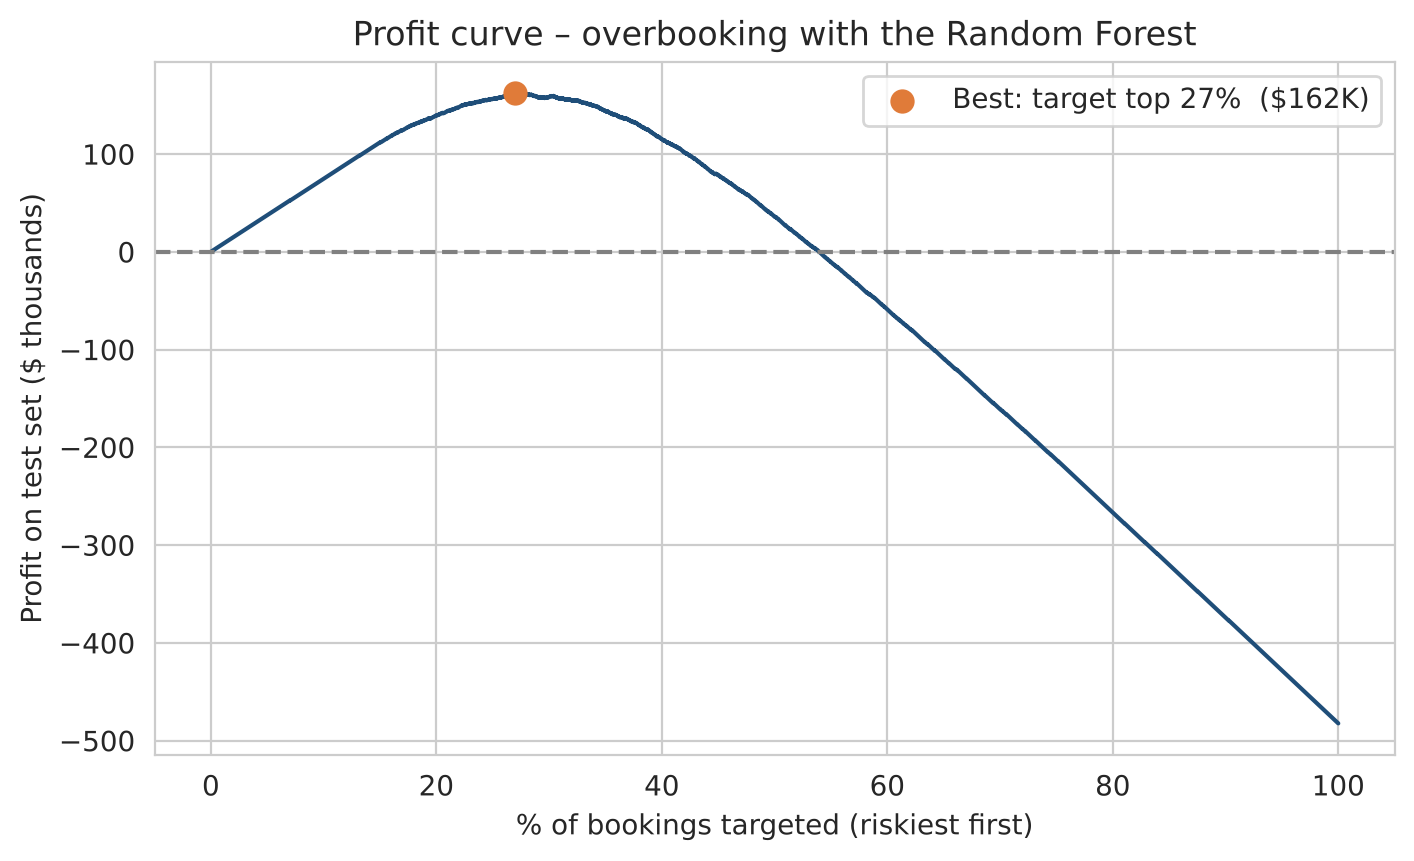

In [26]:
benefit_true_positive = clean_df["avg_price_per_room"].mean()   # revenue saved, about one night
cost_false_positive = 150                                       # cost to relocate a guest who shows up
print("Benefit per correct overbooking: $", round(benefit_true_positive, 2))
print("Cost per wrong overbooking: $", cost_false_positive)

ranking_df["cumulative_tp"] = ranking_df["actual"].cumsum()
ranking_df["cumulative_fp"] = (1 - ranking_df["actual"]).cumsum()
ranking_df["profit"] = ranking_df["cumulative_tp"] * benefit_true_positive - ranking_df["cumulative_fp"] * cost_false_positive

best_row = ranking_df["profit"].idxmax()
best_percent = ranking_df.loc[best_row, "percent_targeted"]
best_profit = ranking_df.loc[best_row, "profit"]
best_threshold = ranking_df.loc[best_row, "probability"]
print("Best % of bookings to target:", round(best_percent, 1), "%")
print("Probability cutoff at that point:", round(best_threshold, 2))
print("Estimated profit on the test set: $", round(best_profit, 0))

plt.figure(figsize=(8, 4.5))
plt.plot(ranking_df["percent_targeted"], ranking_df["profit"] / 1000, color="#1F4E79")
plt.axhline(0, color="gray", linestyle="--")
plt.scatter(best_percent, best_profit / 1000, color="#E07B39", zorder=5, s=60,
            label=f"Best: target top {best_percent:.0f}%  (${best_profit/1000:,.0f}K)")
plt.title("Profit curve – overbooking with the Random Forest")
plt.xlabel("% of bookings targeted (riskiest first)")
plt.ylabel("Profit on test set ($ thousands)")
plt.legend()
plt.show()

### 7.10 Which booking details matter most?
**What this step does:** Shows the **feature importance** from the Random Forest (how much each feature helped the trees make good splits).

**What it tells the hotel:** **Lead time**, **room price**, **number of special requests**, **arrival month**, and whether the booking came through the **Online** segment are the strongest predictors. These match what we saw in our charts.

                    Feature  Importance
                  lead_time       0.362
         avg_price_per_room       0.166
     no_of_special_requests       0.122
              arrival_month       0.089
               total_nights       0.042
          no_of_week_nights       0.037
 market_segment_type_Online       0.036
       no_of_weekend_nights       0.030
               total_guests       0.020
market_segment_type_Offline       0.019


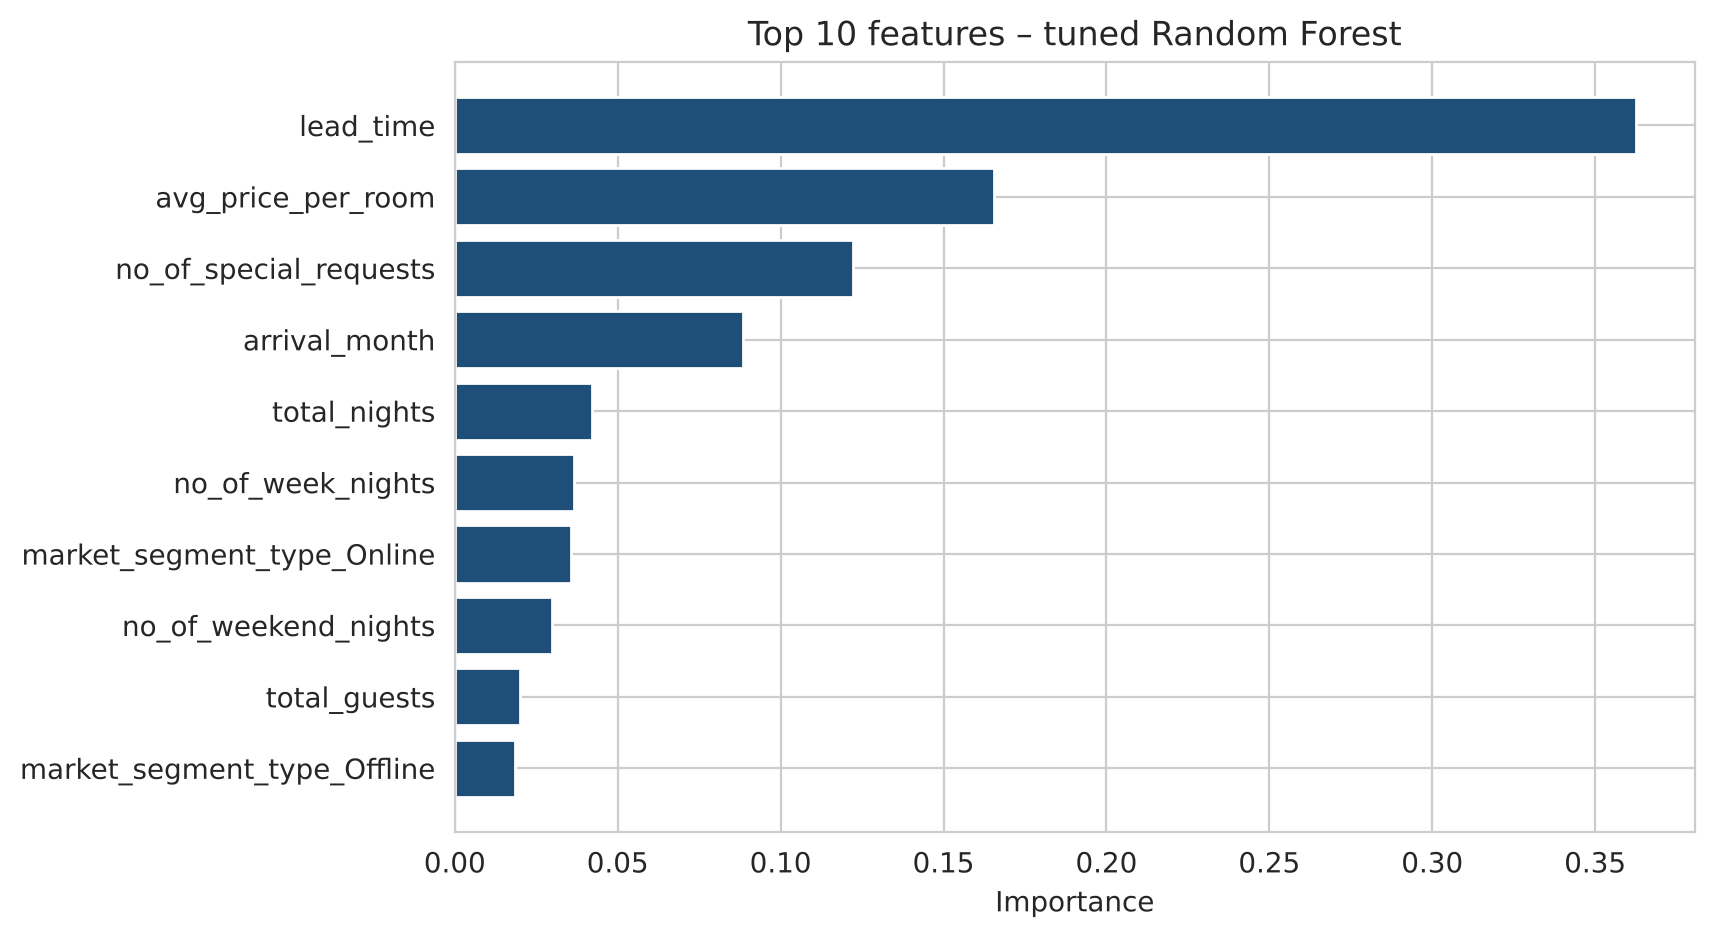

In [27]:
importance_table = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_,
}).sort_values("Importance", ascending=False)

top_ten = importance_table.head(10)
print(top_ten.round(3).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(top_ten["Feature"][::-1], top_ten["Importance"][::-1], color="#1F4E79")
plt.title("Top 10 features – tuned Random Forest")
plt.xlabel("Importance")
plt.show()

## 8. Deployment

We deployed the final model as a **Streamlit web app** (see `app.py` in our GitHub repository). A hotel employee enters the details of a booking and the app shows the **chance of cancellation**, a **risk level**, and a **suggested action**. The app uses the same cleaning steps and the same tuned Random Forest settings as this notebook.

**How the hotel would use it:**
- Score every new booking each night and send a list of high-risk bookings to the reservations team.
- Low-cost actions (reminder emails, confirmation calls) for medium/high risk; deposits or overbooking only for the highest-risk bookings.
- Revenue management uses the predicted number of cancellations per night to set overbooking levels.

**Ethical considerations:**
- **Fairness:** The model should not lead to treating guests worse (e.g., higher prices) only because of how they booked. Use it to *help* guests keep bookings, not punish them.
- **Privacy:** The data has no names or personal IDs; any live system should keep guest data secure and follow privacy rules.
- **Transparency:** Staff should know the score is a prediction, not a fact.

**Risks and how we reduce them:**
| Risk | How we reduce it |
|---|---|
| Overbooking a guest who shows up (False Positive) | Only overbook above a high threshold; keep a relocation plan with nearby hotels |
| Model gets out of date (travel patterns change) | Retrain every few months with new bookings and monitor accuracy |
| Data only covers 2017–2018 at one hotel | Test the model on newer data before relying on it |
| Near-duplicate bookings may make scores look slightly better | Check performance again on new, real bookings after launch |

## 9. Results and Business Recommendations

**Results**
- The **tuned Random Forest** is our best model: on the test set it has **89.9% accuracy, 0.88 precision, 0.80 recall, 0.84 F1, and 0.958 AUC**.
- The single Decision Tree overfit badly (99% training vs 87% test); tuning `max_depth` reduced the gap.
- 5-fold cross-validation accuracy was **0.893 ± 0.005**, so the result is stable.
- Contacting the riskiest 10% of bookings reaches cancellations about **3 times** more often than random (lift = 3.0), and the riskiest 30% contains about **80%** of all cancellations.

**Recommendations for the hotel**
1. **Watch long lead times.** Bookings made 90+ days ahead are the riskiest. Send reminders or ask for a deposit as the date gets closer.
2. **Encourage special requests.** Guests who add requests rarely cancel. Prompting guests to personalize their stay during online booking may increase commitment.
3. **Tighten online booking policies.** The Online segment has the highest cancellation rate; consider non-refundable discounts for online bookings.
4. **Use the model to set overbooking levels**, using the profit curve to decide how many rooms are safe to overbook.
5. **Retrain the model regularly** and replace our example costs with the hotel's real numbers.

## Appendix: Guest Segments with K-Means Clustering

This is an extra, **unsupervised** analysis. Instead of predicting cancellations, we group bookings into similar **segments** and then check the cancellation rate in each one.

### A.1 Choosing k with the elbow method
**What this step does:** Runs k-means for k = 1 to 8 and records the **Within-Cluster Sum of Squares (WCSS)**, which measures how tightly packed each cluster is (lower = tighter). We use `n_init=10` so k-means runs 10 times with different starting centroids and keeps the best result, because one run can land on a poor solution.

**Why:** WCSS always drops as k grows, so we look for the "elbow" where adding more clusters stops helping much.

**What it tells us:** The curve bends gradually. The biggest drops happen up to about k = 3–4, and after that each extra cluster helps less. We choose **k = 4** because it still gives a few easy-to-explain guest types.

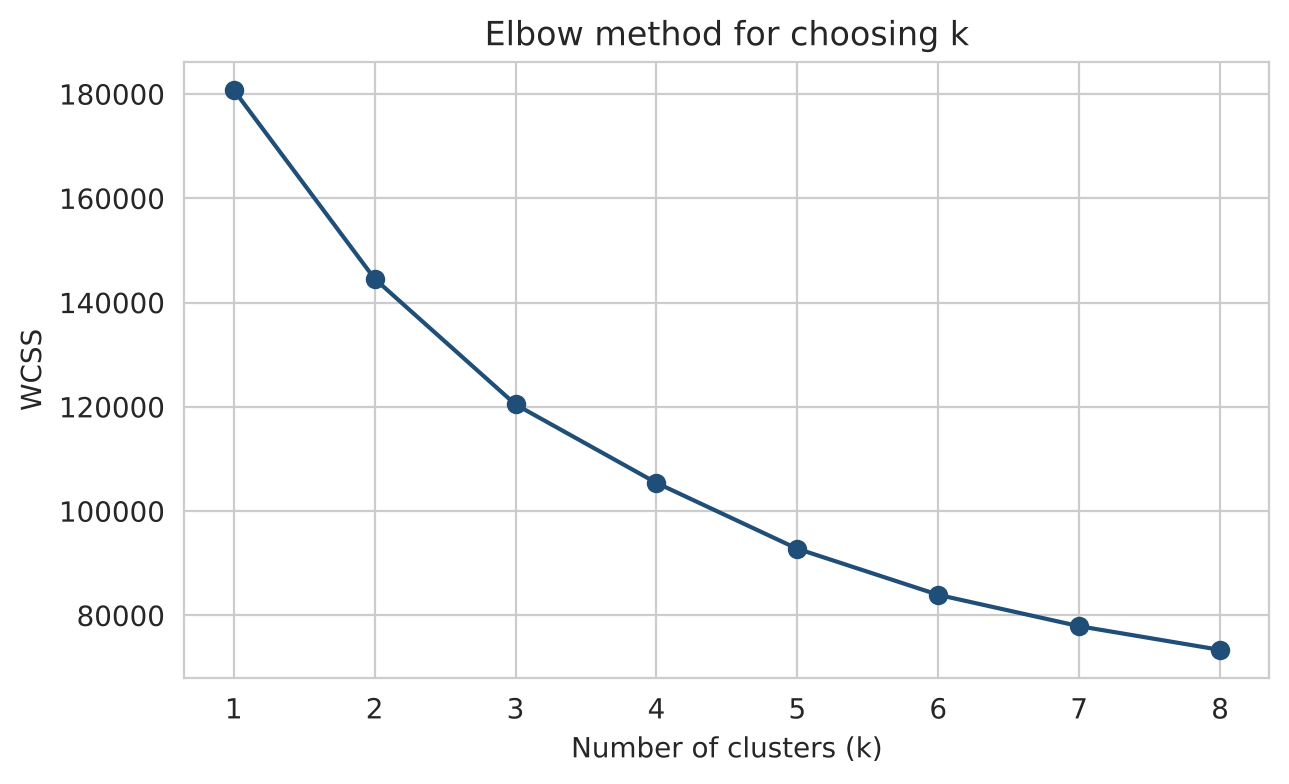

In [28]:
cluster_features = ["lead_time", "avg_price_per_room", "total_nights", "total_guests", "no_of_special_requests"]
cluster_data = clean_df[cluster_features]

cluster_scaler = StandardScaler()
cluster_data_scaled = cluster_scaler.fit_transform(cluster_data)

wcss_values = []
k_values = range(1, 9)
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=random_state)
    kmeans.fit(cluster_data_scaled)
    wcss_values.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, wcss_values, marker="o", color="#1F4E79")
plt.title("Elbow method for choosing k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.show()

### A.2 Describing the clusters
**What this step does:** Uses **k = 4** and describes each cluster by its average values (its **centroid**) and its cancellation rate.

**What it tells the hotel:** Each cluster is a type of guest:
- **Early planners** – book about 7 months ahead with few special requests. This group cancels about **69%** of the time, the highest by far.
- **Families / bigger groups** – about 3 guests and the highest room price (~$158). They cancel about **38%** of the time.
- **Short-notice, short stays** – book about 6 weeks ahead for about 2 nights, the largest group. They cancel about **25%** of the time.
- **Longer stays with requests** – about 4 nights and the most special requests. They are the most reliable, cancelling about **17%** of the time.

This supports our model: long lead time and few special requests = high risk. Marketing can target the "early planners" with reminders or non-refundable deals.

In [29]:
final_kmeans = KMeans(n_clusters=4, n_init=10, random_state=random_state)
cluster_labels = final_kmeans.fit_predict(cluster_data_scaled)

segment_df = clean_df.copy()
segment_df["cluster"] = cluster_labels

cluster_summary = segment_df.groupby("cluster")[cluster_features].mean().round(1)
cluster_summary["bookings"] = segment_df["cluster"].value_counts().sort_index()
cluster_summary["cancel_rate_%"] = (segment_df.groupby("cluster")["booking_status"].mean() * 100).round(1)
cluster_summary

,lead_time,avg_price_per_room,total_nights,total_guests,no_of_special_requests,bookings,cancel_rate_%
cluster,,,,,,,
0,63.4,158.4,3.0,3.1,0.9,4516,38.2
1,65.4,102.9,4.0,2.0,1.4,9275,16.5
2,40.6,91.7,2.3,1.7,0.2,15357,24.8
3,223.9,95.7,3.3,1.9,0.2,7011,68.7
